# Análisis Exploratorio de Datos: CounselChat

Este cuaderno documenta el análisis exploratorio del conjunto de datos
**CounselChat** en el marco del Trabajo de Fin de Grado sobre *Ranking de
respuestas terapéuticas en conversaciones de apoyo en salud mental*.

El objetivo del análisis es doble: por un lado, caracterizar el conjunto de
datos (volumen, temas, calidad); por otro, y de forma más relevante, evaluar
su idoneidad para la tarea de ranking, prestando especial atención a los
*upvotes* como señal de calidad y a la estructura de respuestas por pregunta.


## BLOQUE 0: Configuración del entorno y carga de datos

Se prepara el entorno de forma reproducible: se fija una semilla aleatoria
común a todo el proyecto y se establece una estética uniforme para todas las
figuras, de modo que las visualizaciones mantengan un aspecto coherente en la
memoria. A continuación se carga CounselChat directamente desde su repositorio
oficial en Hugging Face.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
# Reproducibilidad: misma semilla, mismos resultados en cada ejecución
RANDOM_SEED = 27
np.random.seed(RANDOM_SEED)

In [ ]:
# Estética coherente para todas las figuras de la memoria
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

In [ ]:
# Carga del dataset desde Hugging Face

from datasets import load_dataset
dataset = load_dataset("nbertagnolli/counsel-chat")
df = dataset["train"].to_pandas()

README.md:   0%|          | 0.00/4.92k [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


20220401_counsel_chat.csv:   0%|          | 0.00/4.13M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/2775 [00:00<?, ? examples/s]

In [ ]:
print("Dimensiones (filas, columnas):", df.shape)
print("\nColumnas disponibles:")
print(list(df.columns))

Dimensiones (filas, columnas): (2775, 10)

Columnas disponibles:
['questionID', 'questionTitle', 'questionText', 'questionLink', 'topic', 'therapistInfo', 'therapistURL', 'answerText', 'upvotes', 'views']


El conjunto de datos se carga correctamente y contiene **2.775 filas y 10
columnas**.

Cada fila corresponde a una respuesta individual de un terapeuta a
una pregunta de un paciente. Entre las columnas destacan questionID
(identificador de pregunta, imprescindible para agrupar respuestas en la tarea
de ranking), topic (tema clínico), answerText (texto de la respuesta),
upvotes (señal de calidad empleada como referencia) y views (número de
visualizaciones).

Los avisos mostrados durante la carga (*Repo card metadata block was not
found*) son informativos y no afectan a la integridad de los datos: únicamente
indican que el repositorio no incluye metadatos descriptivos.

## BLOQUE 1: Inspección inicial y calidad de los datos

Objetivo: antes de analizar, verificar la integridad del dataset. Un EDA riguroso empieza comprobando tipos, nulos y duplicados, porque cualquier conclusión posterior depende de datos limpios.

**1.1 Vista rápida de las primeras filas**

In [ ]:
display(df.head(3))

,questionID,questionTitle,questionText,questionLink,topic,therapistInfo,therapistURL,answerText,upvotes,views
0,0,Do I have too many issues for counseling?,I have so many issues to address. I have a his...,https://counselchat.com/questions/do-i-have-to...,depression,Jennifer MolinariHypnotherapist & Licensed Cou...,https://counselchat.com/therapists/jennifer-mo...,It is very common for people to have multiple ...,3,1971
1,0,Do I have too many issues for counseling?,I have so many issues to address. I have a his...,https://counselchat.com/questions/do-i-have-to...,depression,"Jason Lynch, MS, LMHC, LCAC, ADSIndividual & C...",https://counselchat.com/therapists/jason-lynch...,"I've never heard of someone having ""too many i...",2,386
2,0,Do I have too many issues for counseling?,I have so many issues to address. I have a his...,https://counselchat.com/questions/do-i-have-to...,depression,Shakeeta TorresFaith Based Mental Health Couns...,https://counselchat.com/therapists/shakeeta-to...,Absolutely not. I strongly recommending worki...,2,3071


**1.2 Tipos de datos y memoria**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2775 entries, 0 to 2774
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   questionID     2775 non-null   int64 
 1   questionTitle  2775 non-null   object
 2   questionText   2636 non-null   object
 3   questionLink   2775 non-null   object
 4   topic          2775 non-null   object
 5   therapistInfo  2775 non-null   object
 6   therapistURL   2775 non-null   object
 7   answerText     2749 non-null   object
 8   upvotes        2775 non-null   int64 
 9   views          2775 non-null   int64 
dtypes: int64(3), object(7)
memory usage: 216.9+ KB


**1.3 Valores nulos por columna (absolutos y porcentaje)**

In [ ]:
nulos = pd.DataFrame({
    "n_nulos": df.isnull().sum(),
    "porcentaje": (df.isnull().sum() / len(df) * 100).round(2)
})
print(nulos)

               n_nulos  porcentaje
questionID           0        0.00
questionTitle        0        0.00
questionText       139        5.01
questionLink         0        0.00
topic                0        0.00
therapistInfo        0        0.00
therapistURL         0        0.00
answerText          26        0.94
upvotes              0        0.00
views                0        0.00


**1.4 Filas duplicadas exactas**

In [ ]:
print("Filas completamente duplicadas:", df.duplicated().sum())

Filas completamente duplicadas: 0


**1.5 ¿Cuántas preguntas únicas y cuántas respuestas?**

In [ ]:
print("Nº total de respuestas (filas):", len(df))
print("Nº de preguntas únicas (questionID):", df["questionID"].nunique())
print("Nº de temas clínicos únicos (topic):", df["topic"].nunique())
print("Nº de terapeutas únicos:", df["therapistInfo"].nunique())

Nº total de respuestas (filas): 2775
Nº de preguntas únicas (questionID): 940
Nº de temas clínicos únicos (topic): 31
Nº de terapeutas únicos: 437


### Interpretación: calidad y estructura de los datos

La inspección inicial revela un conjunto de datos de buena calidad general,
con matices relevantes para la tarea de ranking:

- **Volumen y cardinalidad:** El dataset contiene 2.775 respuestas
  correspondientes a 940 preguntas únicas, respondidas por 437 terapeutas
  distintos y distribuidas en 31 temas clínicos. Esto arroja una media
  aproximada de **2,95 respuestas por pregunta**, cifra que confirma la
  viabilidad de una tarea de ranking: para ordenar respuestas es necesario
  que exista más de una candidata por pregunta. No obstante, al tratarse de
  una media, es imprescindible analizar posteriormente la distribución real
  del número de respuestas por pregunta.

- **Valores nulos:** Se detectan 26 respuestas vacías (answerText, 0,94 %) y
  139 preguntas sin texto (questionText, 5,01 %). Las respuestas vacías
  deberán eliminarse antes de construir el conjunto de ranking, ya que una
  respuesta inexistente no puede ordenarse ni evaluarse. Las preguntas sin
  texto son recuperables parcialmente a través del campo questionTitle, por
  lo que su tratamiento se decidirá en la fase de construcción del dataset.

- **Integridad:** No existen filas completamente duplicadas y los tipos de
  datos son coherentes: upvotes y views son enteros, lo que permite su
  análisis numérico directo como señales de calidad y popularidad.

## BLOQUE 2: Distribución del número de respuestas por pregunta

La tarea de ranking exige que cada pregunta cuente con al menos dos respuestas
candidatas. Este apartado cuantifica qué proporción del conjunto de datos
cumple esa condición y caracteriza la forma de la distribución.

Estadísticas:

In [ ]:
# Número de respuestas asociadas a cada pregunta
respuestas_por_pregunta = df.groupby("questionID").size()

# Resumen estadístico presentado como tabla
resumen = respuestas_por_pregunta.describe().round(2).to_frame("valor")
resumen.index.name = "estadístico"
display(resumen)

,valor
estadístico,
count,940.00
mean,2.95
std,6.31
min,1.00
25%,1.00
50%,1.00
75%,3.00
max,107.00


Viabilidad del ranking:

In [ ]:
una_sola = (respuestas_por_pregunta == 1).sum()
dos_o_mas = (respuestas_por_pregunta >= 2).sum()
total_preg = len(respuestas_por_pregunta)

viabilidad = pd.DataFrame({
    "n_preguntas": [una_sola, dos_o_mas, total_preg],
    "porcentaje": [
        round(una_sola / total_preg * 100, 1),
        round(dos_o_mas / total_preg * 100, 1),
        100.0
    ]
}, index=["1 respuesta (no rankeable)", "2+ respuestas (rankeable)", "Total"])

display(viabilidad)

,n_preguntas,porcentaje
1 respuesta (no rankeable),480,51.1
2+ respuestas (rankeable),460,48.9
Total,940,100.0


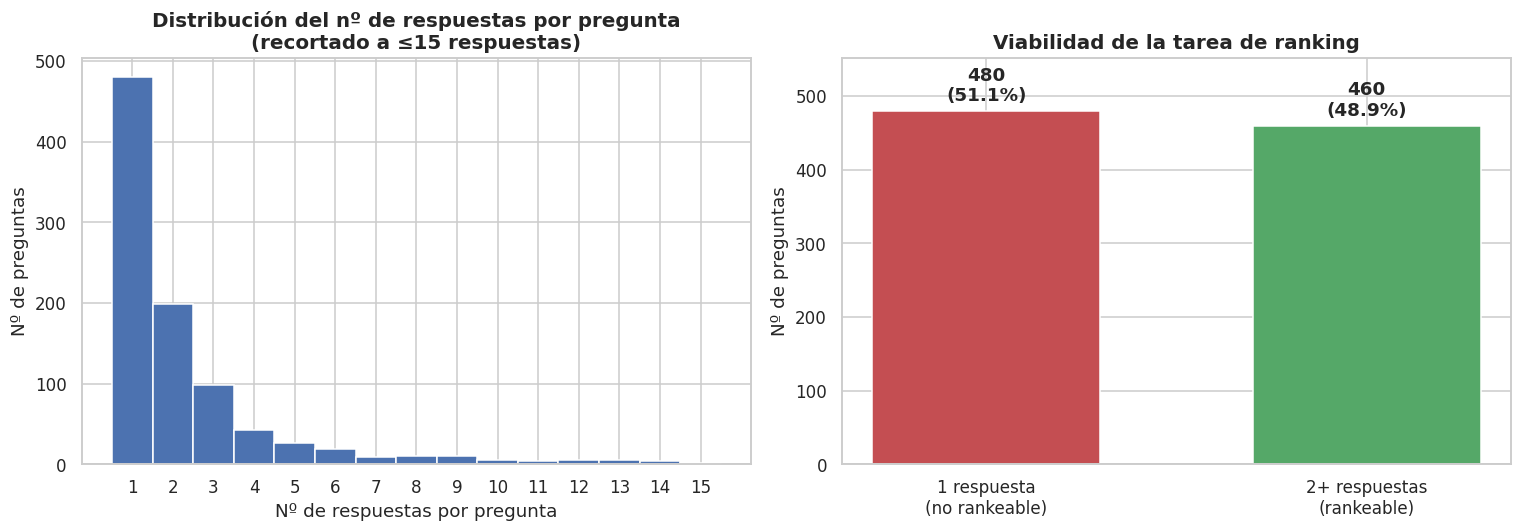

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribución recortada: el máximo (107) comprime la escala y oculta la forma real
LIMITE = 15
recortado = respuestas_por_pregunta[respuestas_por_pregunta <= LIMITE]
axes[0].hist(recortado, bins=range(1, LIMITE + 2),
             edgecolor="white", align="left", color="#4C72B0")
axes[0].set_title(f"Distribución del nº de respuestas por pregunta\n(recortado a ≤{LIMITE} respuestas)")
axes[0].set_xlabel("Nº de respuestas por pregunta")
axes[0].set_ylabel("Nº de preguntas")
axes[0].set_xticks(range(1, LIMITE + 1))

# Preguntas utilizables frente a descartadas para la tarea de ranking
barras = axes[1].bar(
    ["1 respuesta\n(no rankeable)", "2+ respuestas\n(rankeable)"],
    [una_sola, dos_o_mas],
    color=["#C44E52", "#55A868"], edgecolor="white", width=0.6
)
axes[1].set_title("Viabilidad de la tarea de ranking")
axes[1].set_ylabel("Nº de preguntas")

for barra, valor in zip(barras, [una_sola, dos_o_mas]):
    axes[1].text(barra.get_x() + barra.get_width() / 2, valor + 8,
                 f"{valor}\n({valor / total_preg * 100:.1f}%)",
                 ha="center", va="bottom", fontweight="bold")
axes[1].set_ylim(0, max(una_sola, dos_o_mas) * 1.15)

plt.tight_layout()
plt.savefig("figura_3_1.png", dpi=200, bbox_inches="tight")
plt.show()

### Interpretación: viabilidad de la tarea de ranking

Este análisis constituye uno de los hallazgos centrales del estudio
exploratorio, ya que determina qué subconjunto de datos es realmente
utilizable para la tarea de ranking.

**Más de la mitad de las preguntas (51,1 %, es decir, 480 de 940) reciben una
única respuesta.** Estas preguntas no son rankeables por definición: ordenar
respuestas requiere al menos dos candidatas por pregunta. En consecuencia, el
conjunto efectivo para la evaluación del ranking se reduce a las **460
preguntas (48,9 %) que disponen de dos o más respuestas**.

La distribución del número de respuestas por pregunta presenta además una
marcada **asimetría positiva**. La media (2,95) es casi tres veces superior a
la mediana (1,00), lo que indica que el valor promedio no es representativo del
caso típico: la mayoría de preguntas tienen una sola respuesta, mientras que
un reducido número de preguntas concentra un volumen muy elevado, alcanzando un
máximo de 107 respuestas. Esta observación matiza la media de 2,95 respuestas
por pregunta calculada inicialmente, que resultaba engañosa al no reflejar la
forma real de la distribución.

**Decisión derivada del análisis:** el conjunto de datos para la tarea de
ranking se construirá filtrando las preguntas con dos o más respuestas,
descartando las 480 preguntas de respuesta única. Esta decisión se documenta
aquí y se aplicará en la fase de construcción del dataset.

## BLOQUE 3: Análisis de los *upvotes* como señal de calidad

Los *upvotes* constituyen la señal de referencia empleada en este trabajo para
determinar qué respuesta es la más adecuada. Su idoneidad como medida de
calidad no puede darse por supuesta: si la mayoría de respuestas carecen de
valoración, o si las valoraciones se concentran en unos pocos casos, la señal
resultará débil y condicionará la evaluación de los sistemas de ranking.

Este apartado examina la distribución de los *upvotes* y, de forma especialmente
relevante, su comportamiento dentro de cada pregunta, que es el nivel al que
opera realmente la tarea de ranking.

Distribución global de upvotes:

In [ ]:
resumen_upvotes = df["upvotes"].describe().round(2).to_frame("valor")
resumen_upvotes.index.name = "estadístico"
display(resumen_upvotes)

# Proporción de respuestas sin ninguna valoración
sin_upvotes = (df["upvotes"] == 0).sum()
con_upvotes = (df["upvotes"] > 0).sum()

distribucion_señal = pd.DataFrame({
    "n_respuestas": [sin_upvotes, con_upvotes, len(df)],
    "porcentaje": [
        round(sin_upvotes / len(df) * 100, 1),
        round(con_upvotes / len(df) * 100, 1),
        100.0
    ]
}, index=["Sin upvotes (0)", "Con upvotes (>0)", "Total"])

display(distribucion_señal)

,valor
estadístico,
count,2775.00
mean,0.52
std,1.04
min,0.00
25%,0.00
50%,0.00
75%,1.00
max,12.00


,n_respuestas,porcentaje
Sin upvotes (0),1939,69.9
Con upvotes (>0),836,30.1
Total,2775,100.0


Análisis crítico: ¿hay empates dentro de cada pregunta?

In [ ]:
# El ranking se evalúa dentro de cada pregunta: interesa saber si los upvotes
# permiten distinguir una "mejor respuesta" o si se producen empates.
rankeables = df[df["questionID"].isin(
    respuestas_por_pregunta[respuestas_por_pregunta >= 2].index
)]

def diagnostico_pregunta(grupo):
    maximo = grupo["upvotes"].max()
    return pd.Series({
        "n_respuestas": len(grupo),
        "upvotes_max": maximo,
        "n_con_maximo": (grupo["upvotes"] == maximo).sum(),
        "todas_cero": (grupo["upvotes"] == 0).all()
    })

diag = rankeables.groupby("questionID").apply(diagnostico_pregunta)

todas_cero = int(diag["todas_cero"].sum())
empate_max = int(((diag["n_con_maximo"] > 1) & (~diag["todas_cero"])).sum())
ganador_claro = int((diag["n_con_maximo"] == 1).sum())
total_rank = len(diag)

calidad_señal = pd.DataFrame({
    "n_preguntas": [ganador_claro, empate_max, todas_cero, total_rank],
    "porcentaje": [
        round(ganador_claro / total_rank * 100, 1),
        round(empate_max / total_rank * 100, 1),
        round(todas_cero / total_rank * 100, 1),
        100.0
    ]
}, index=[
    "Mejor respuesta única (señal útil)",
    "Empate en el máximo (señal ambigua)",
    "Todas con 0 upvotes (sin señal)",
    "Total preguntas rankeables"
])

display(calidad_señal)

/tmp/ipykernel_3812/1004069360.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  diag = rankeables.groupby("questionID").apply(diagnostico_pregunta)


,n_preguntas,porcentaje
Mejor respuesta única (señal útil),214,46.5
Empate en el máximo (señal ambigua),62,13.5
Todas con 0 upvotes (sin señal),184,40.0
Total preguntas rankeables,460,100.0


Visualización:

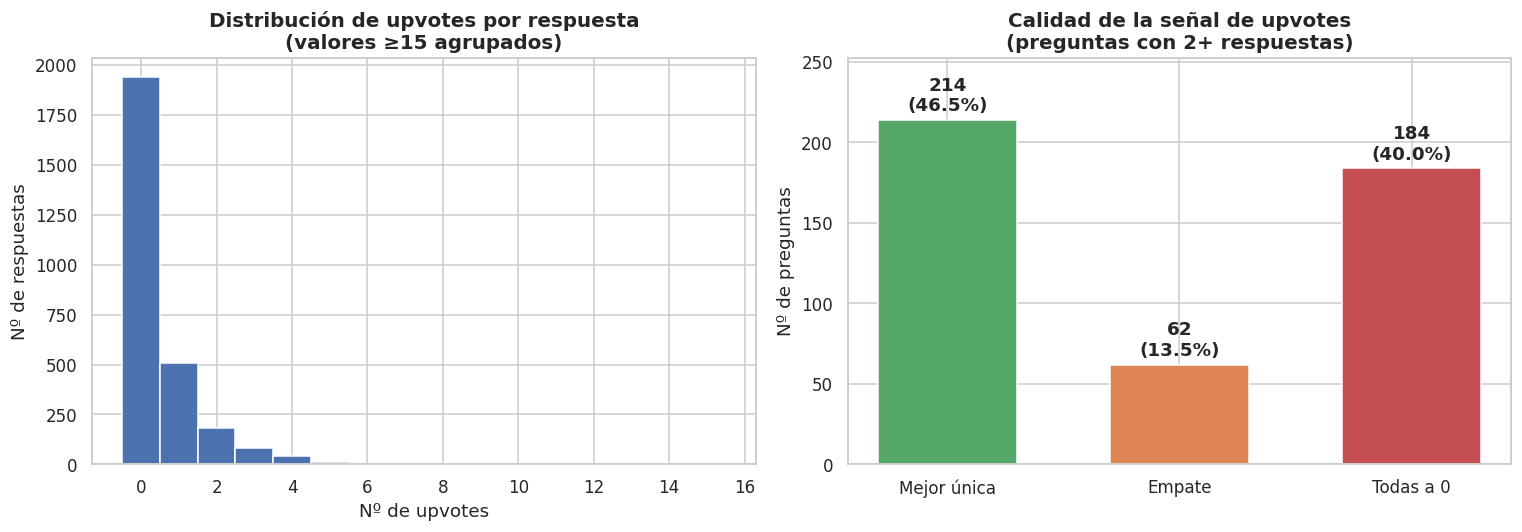

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribución de upvotes, recortada porque unos pocos valores extremos
# comprimirían la escala y ocultarían la concentración en valores bajos
LIM_UP = 15
axes[0].hist(df["upvotes"].clip(upper=LIM_UP), bins=range(0, LIM_UP + 2),
             edgecolor="white", align="left", color="#4C72B0")
axes[0].set_title(f"Distribución de upvotes por respuesta\n(valores ≥{LIM_UP} agrupados)")
axes[0].set_xlabel("Nº de upvotes")
axes[0].set_ylabel("Nº de respuestas")

# Calidad de la señal dentro de las preguntas rankeables
etiquetas = ["Mejor única", "Empate", "Todas a 0"]
valores = [ganador_claro, empate_max, todas_cero]
colores = ["#55A868", "#DD8452", "#C44E52"]
barras = axes[1].bar(etiquetas, valores, color=colores, edgecolor="white", width=0.6)
axes[1].set_title("Calidad de la señal de upvotes\n(preguntas con 2+ respuestas)")
axes[1].set_ylabel("Nº de preguntas")

for barra, valor in zip(barras, valores):
    axes[1].text(barra.get_x() + barra.get_width() / 2, valor + 3,
                 f"{valor}\n({valor / total_rank * 100:.1f}%)",
                 ha="center", va="bottom", fontweight="bold")
axes[1].set_ylim(0, max(valores) * 1.18)

plt.tight_layout()
plt.savefig("figura_3_2.png", dpi=200, bbox_inches="tight")
plt.show()

### Interpretación: los *upvotes* como señal débil

El análisis de los *upvotes* revela una limitación fundamental del conjunto de
datos que condiciona el diseño de la evaluación.

**La señal es escasa.** El 69,9 % de las respuestas (1.939 de 2.775) no ha
recibido ninguna valoración. La media se sitúa en 0,52 *upvotes* por respuesta
y el valor máximo observado es 12, lo que evidencia un rango muy estrecho.

**Más relevante aún es el comportamiento de la señal a nivel de pregunta**, que
es el nivel al que opera la tarea de ranking. De las 460 preguntas con dos o
más respuestas:

- En **184 preguntas (40,0 %) todas las respuestas tienen cero *upvotes***. En
  estos casos no existe una respuesta de referencia: la señal no permite
  determinar cuál es la mejor y cualquier ordenación resulta indistinguible.
- En **62 preguntas (13,5 %) se produce un empate en el valor máximo**, de modo
  que dos o más respuestas comparten la mejor valoración. La noción de "única
  respuesta correcta" que subyace a la métrica Precision@1 resulta ambigua en
  estos casos.
- Únicamente en **214 preguntas (46,5 %) existe una única respuesta con la
  valoración máxima**, configurando una señal de referencia inequívoca.

**Decisión derivada del análisis:** La evaluación de los sistemas de ranking se
restringirá al subconjunto de preguntas que presentan una mejor respuesta
inequívoca, dado que las preguntas sin señal no permiten discriminar entre
sistemas y las preguntas con empate introducen ambigüedad en la métrica. El
tratamiento de los empates se documentará explícitamente en la fase de
construcción del conjunto de evaluación.

Este hallazgo confirma la naturaleza de **señal débil** de los *upvotes*,
asumida desde el planteamiento del trabajo, y cuantifica su alcance real: el
conjunto efectivo de evaluación se reduce de las 940 preguntas iniciales a 214,
un 22,8 % del total.

## BLOQUE 4: Longitud de las respuestas y detección de sesgos

La longitud de una respuesta es una característica superficial fácilmente
explotable por un sistema de ranking. Si las respuestas más extensas tienden a
recibir más *upvotes*, un ranker podría alcanzar buen rendimiento limitándose a
priorizar la extensión, sin capturar realmente la calidad del contenido.

Este apartado caracteriza la longitud de las respuestas y examina su relación
con la señal de calidad, con el fin de anticipar posibles sesgos en la
evaluación.

Caracterización:

In [ ]:
df["long_palabras"] = df["answerText"].fillna("").str.split().str.len()
df["long_caracteres"] = df["answerText"].fillna("").str.len()

longitudes = df[df["answerText"].notna()][["long_palabras", "long_caracteres"]]
display(longitudes.describe().round(1))

,long_palabras,long_caracteres
count,2749.0,2749.0
mean,168.0,959.7
std,118.5,677.1
min,1.0,10.0
25%,87.0,498.0
50%,136.0,779.0
75%,212.0,1221.0
max,939.0,5499.0


Relación con los upvotes:

In [ ]:
from scipy.stats import spearmanr, pearsonr

valid = df[df["answerText"].notna()]

rho, p_rho = spearmanr(valid["long_palabras"], valid["upvotes"])
r, p_r = pearsonr(valid["long_palabras"], valid["upvotes"])

correlaciones = pd.DataFrame({
    "coeficiente": [round(r, 3), round(rho, 3)],
    "p_valor": [f"{p_r:.2e}", f"{p_rho:.2e}"]
}, index=["Pearson (lineal)", "Spearman (monótona)"])
display(correlaciones)

# Upvotes medios por cuartil de longitud: relación más interpretable
valid = valid.copy()
valid["cuartil_long"] = pd.qcut(valid["long_palabras"], 4,
                                labels=["Q1 (más cortas)", "Q2", "Q3", "Q4 (más largas)"])
por_cuartil = valid.groupby("cuartil_long", observed=True).agg(
    n_respuestas=("upvotes", "size"),
    upvotes_medios=("upvotes", "mean"),
    pct_con_upvotes=("upvotes", lambda x: (x > 0).mean() * 100)
).round(2)
display(por_cuartil)

,coeficiente,p_valor
Pearson (lineal),0.128,1.55e-11
Spearman (monótona),0.151,1.76e-15


,n_respuestas,upvotes_medios,pct_con_upvotes
cuartil_long,,,
Q1 (más cortas),689,0.34,20.17
Q2,688,0.46,28.63
Q3,686,0.58,34.99
Q4 (más largas),686,0.71,37.76


Test decisivo: ¿gana la más larga dentro de cada pregunta?

In [ ]:
# Comparación intra-pregunta: en las preguntas con señal inequívoca,
# ¿la respuesta más votada es también la más larga?
con_señal = diag[diag["n_con_maximo"] == 1].index
subset = df[df["questionID"].isin(con_señal) & df["answerText"].notna()]

def gana_la_mas_larga(grupo):
    mejor = grupo.loc[grupo["upvotes"].idxmax()]
    mas_larga = grupo.loc[grupo["long_palabras"].idxmax()]
    return mejor.name == mas_larga.name

coincidencias = subset.groupby("questionID").apply(gana_la_mas_larga)
n_coincide = int(coincidencias.sum())
n_total = len(coincidencias)

# Baseline aleatorio: probabilidad de acertar eligiendo al azar
azar = subset.groupby("questionID").size().apply(lambda n: 1/n).mean() * 100

sesgo = pd.DataFrame({
    "valor": [n_coincide, n_total, round(n_coincide/n_total*100, 1), round(azar, 1)]
}, index=["Preguntas donde la más votada es la más larga",
          "Total preguntas evaluadas",
          "Porcentaje de coincidencia (%)",
          "Baseline aleatorio esperado (%)"])
display(sesgo)

/tmp/ipykernel_3812/58907200.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  coincidencias = subset.groupby("questionID").apply(gana_la_mas_larga)


,valor
Preguntas donde la más votada es la más larga,85.0
Total preguntas evaluadas,214.0
Porcentaje de coincidencia (%),39.7
Baseline aleatorio esperado (%),32.5


Visualización:

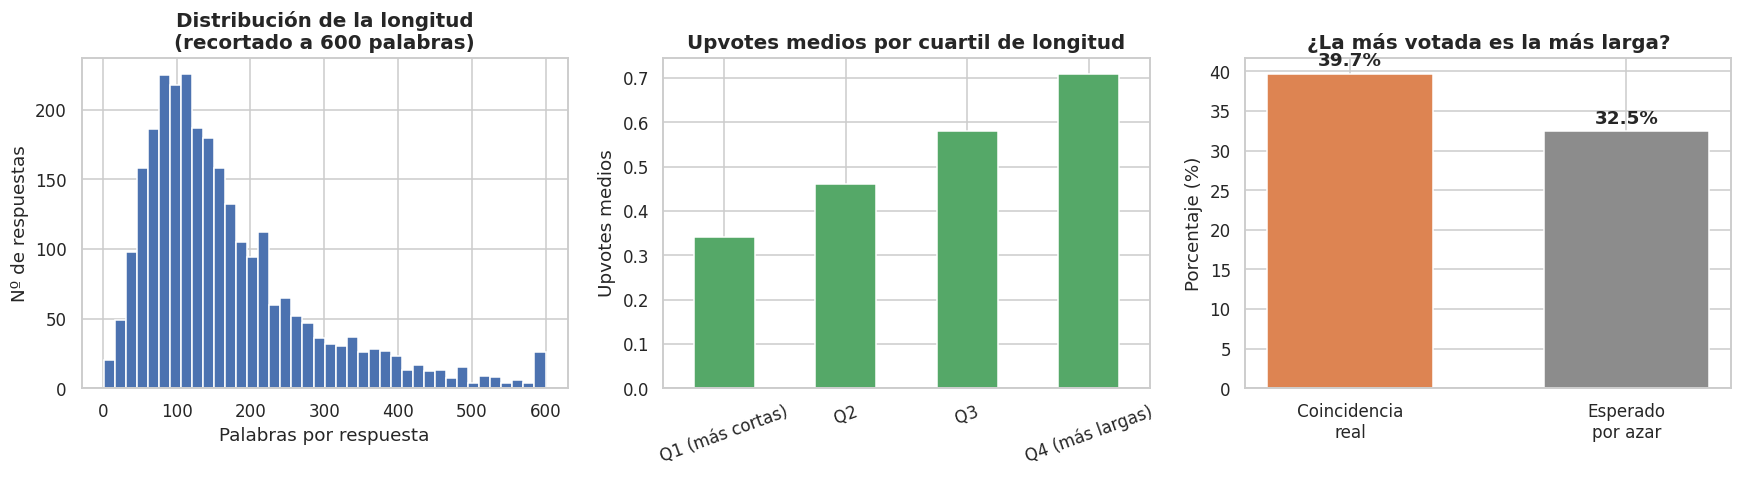

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].hist(valid["long_palabras"].clip(upper=600), bins=40,
             edgecolor="white", color="#4C72B0")
axes[0].set_title("Distribución de la longitud\n(recortado a 600 palabras)")
axes[0].set_xlabel("Palabras por respuesta")
axes[0].set_ylabel("Nº de respuestas")

por_cuartil["upvotes_medios"].plot(kind="bar", ax=axes[1],
                                   color="#55A868", edgecolor="white", rot=20)
axes[1].set_title("Upvotes medios por cuartil de longitud")
axes[1].set_xlabel("")
axes[1].set_ylabel("Upvotes medios")

axes[2].bar(["Coincidencia\nreal", "Esperado\npor azar"],
            [n_coincide/n_total*100, azar],
            color=["#DD8452", "#8C8C8C"], edgecolor="white", width=0.6)
axes[2].set_title("¿La más votada es la más larga?")
axes[2].set_ylabel("Porcentaje (%)")
for i, v in enumerate([n_coincide/n_total*100, azar]):
    axes[2].text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

### Interpretación: existe un sesgo de longitud, pero de magnitud reducida

El análisis identifica una relación positiva entre la extensión de las
respuestas y los *upvotes* recibidos, si bien de intensidad limitada.

**Correlación estadísticamente significativa pero débil.** Los coeficientes de
Pearson (0,128) y Spearman (0,151) resultan significativos (p < 0,001), lo que
se explica en parte por el elevado tamaño muestral (2.749 respuestas). Sin
embargo, su magnitud es reducida: la longitud explica una proporción muy
pequeña de la variabilidad de la señal de calidad. Conviene distinguir aquí
entre significación estadística y relevancia práctica.

**Tendencia monótona por cuartiles.** Los *upvotes* medios aumentan de forma
consistente desde el cuartil de respuestas más cortas (0,34) hasta el de las
más largas (0,71). De modo análogo, la proporción de respuestas que reciben al
menos un voto pasa del 20,2 % al 37,8 %, prácticamente el doble.

**Contraste frente a un baseline aleatorio.** En las 214 preguntas con señal
inequívoca, la respuesta más votada coincide con la más extensa en el 39,7 % de
los casos, frente al 32,5 % que cabría esperar por selección aleatoria. La
diferencia de 7,2 puntos porcentuales confirma la existencia del sesgo, pero
también su carácter moderado: la longitud no determina la valoración recibida.

**Implicaciones para la evaluación:** Este resultado establece un baseline
informativo no trivial, un sistema que ordenase las respuestas únicamente por
extensión alcanzaría un 39,7 % de acierto en Precision@1, que los sistemas
propuestos deberán superar para demostrar que capturan aspectos de calidad no
reducibles a la mera longitud del texto.


## BLOQUE 5: Temas clínicos y exposición de las respuestas

Este último apartado aborda dos cuestiones complementarias. En primer lugar, la
distribución de las preguntas por tema clínico, que caracteriza el dominio
cubierto por el conjunto de datos y permite detectar posibles desequilibrios.

En segundo lugar, la relación entre los *upvotes* y el número de
visualizaciones (views). Esta comparación resulta especialmente pertinente:
si los *upvotes* dependen en gran medida de la exposición recibida por una
respuesta, estarían midiendo visibilidad antes que calidad, lo que constituiría
una limitación adicional de la señal de referencia.

Temas clínicos:

In [ ]:
temas = df.groupby("topic").agg(
    n_respuestas=("upvotes", "size"),
    n_preguntas=("questionID", "nunique"),
    upvotes_medios=("upvotes", "mean"),
    pct_con_upvotes=("upvotes", lambda x: (x > 0).mean() * 100)
).round(2).sort_values("n_respuestas", ascending=False)

display(temas)

,n_respuestas,n_preguntas,upvotes_medios,pct_con_upvotes
topic,,,,
depression,465,144,0.42,26.24
anxiety,358,105,0.40,23.46
counseling-fundamentals,270,7,0.17,11.48
intimacy,248,116,0.62,39.52
relationships,202,107,0.93,46.53
parenting,191,56,0.46,28.80
family-conflict,144,63,0.76,40.97
trauma,102,26,0.45,27.45
self-esteem,100,49,0.58,32.00


Views con upvotes:

In [ ]:
resumen_views = df["views"].describe().round(1).to_frame("valor")
resumen_views.index.name = "estadístico"
display(resumen_views)

rho_v, p_v = spearmanr(df["views"], df["upvotes"])
r_v, p_vp = pearsonr(df["views"], df["upvotes"])

corr_views = pd.DataFrame({
    "coeficiente": [round(r_v, 3), round(rho_v, 3)],
    "p_valor": [f"{p_vp:.2e}", f"{p_v:.2e}"]
}, index=["Pearson (lineal)", "Spearman (monótona)"])
display(corr_views)

# Upvotes medios por cuartil de visualizaciones
df_v = df.copy()
df_v["cuartil_views"] = pd.qcut(df_v["views"], 4,
                                labels=["Q1 (menos vistas)", "Q2", "Q3", "Q4 (más vistas)"])
por_views = df_v.groupby("cuartil_views", observed=True).agg(
    n_respuestas=("upvotes", "size"),
    views_medias=("views", "mean"),
    upvotes_medios=("upvotes", "mean"),
    pct_con_upvotes=("upvotes", lambda x: (x > 0).mean() * 100)
).round(2)
display(por_views)

,valor
estadístico,
count,2775.0
mean,328.0
std,796.3
min,1.0
25%,74.5
50%,132.0
75%,254.5
max,16738.0


,coeficiente,p_valor
Pearson (lineal),0.434,3.88e-128
Spearman (monótona),0.502,2.56e-177


,n_respuestas,views_medias,upvotes_medios,pct_con_upvotes
cuartil_views,,,,
Q1 (menos vistas),694,47.61,0.06,5.04
Q2,703,103.44,0.22,16.93
Q3,684,180.54,0.50,35.96
Q4 (más vistas),694,981.32,1.30,62.82


Test intra-pregunta y visualización:

/tmp/ipykernel_3812/63533976.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  coinc_views = subset.groupby("questionID").apply(gana_la_mas_vista)


,coincidencia (%)
Criterio: más vista,76.2
Criterio: más larga,39.7
Baseline aleatorio,32.5


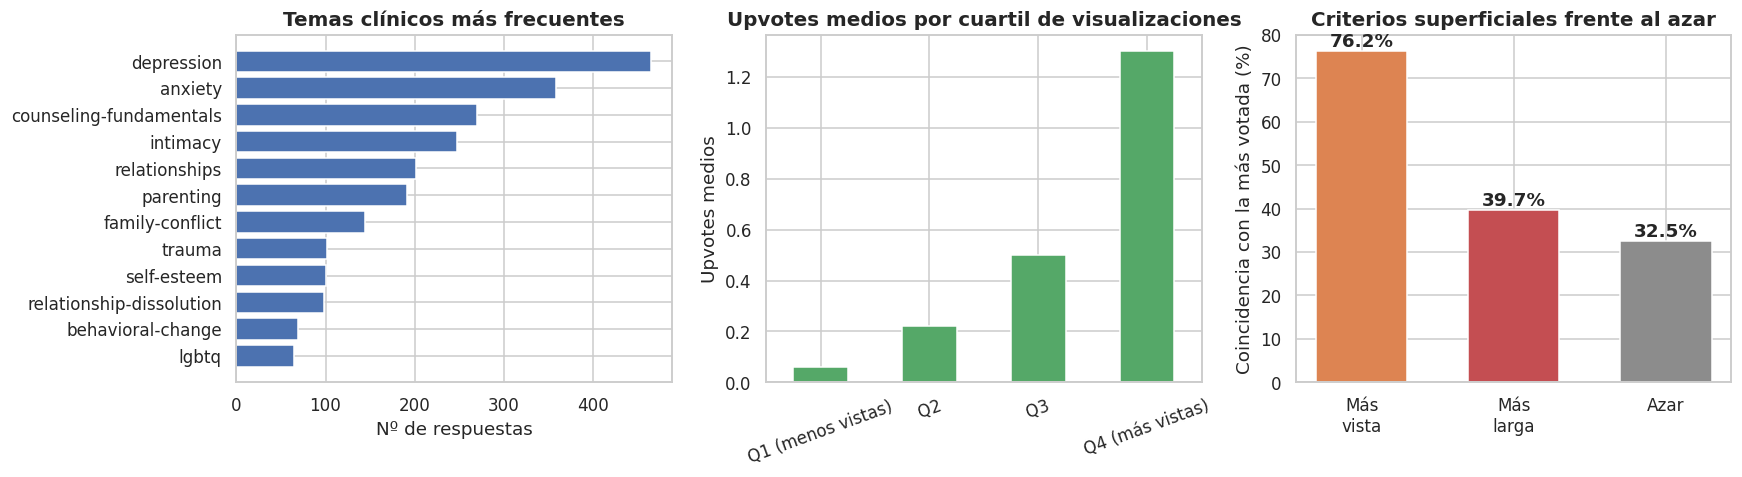

In [ ]:
# ¿La respuesta más votada es también la más vista, dentro de cada pregunta?
def gana_la_mas_vista(grupo):
    mejor = grupo.loc[grupo["upvotes"].idxmax()]
    mas_vista = grupo.loc[grupo["views"].idxmax()]
    return mejor.name == mas_vista.name

coinc_views = subset.groupby("questionID").apply(gana_la_mas_vista)
n_coinc_v = int(coinc_views.sum())

comparativa = pd.DataFrame({
    "coincidencia (%)": [
        round(n_coinc_v / len(coinc_views) * 100, 1),
        round(n_coincide / n_total * 100, 1),
        round(azar, 1)
    ]
}, index=["Criterio: más vista", "Criterio: más larga", "Baseline aleatorio"])
display(comparativa)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

top_temas = temas.head(12)
axes[0].barh(top_temas.index[::-1], top_temas["n_respuestas"][::-1],
             color="#4C72B0", edgecolor="white")
axes[0].set_title("Temas clínicos más frecuentes")
axes[0].set_xlabel("Nº de respuestas")

por_views["upvotes_medios"].plot(kind="bar", ax=axes[1],
                                 color="#55A868", edgecolor="white", rot=20)
axes[1].set_title("Upvotes medios por cuartil de visualizaciones")
axes[1].set_xlabel("")
axes[1].set_ylabel("Upvotes medios")

vals = comparativa["coincidencia (%)"].values
axes[2].bar(["Más\nvista", "Más\nlarga", "Azar"], vals,
            color=["#DD8452", "#C44E52", "#8C8C8C"], edgecolor="white", width=0.6)
axes[2].set_title("Criterios superficiales frente al azar")
axes[2].set_ylabel("Coincidencia con la más votada (%)")
for i, v in enumerate(vals):
    axes[2].text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig("figura_3_3.png", dpi=200, bbox_inches="tight")
plt.show()

### Interpretación: los *upvotes* reflejan principalmente exposición

Este análisis constituye el hallazgo más relevante del estudio exploratorio,
al cuestionar de forma directa la validez de la señal de referencia empleada.

**Los temas clínicos presentan una distribución desequilibrada.** Depresión
(465 respuestas) y ansiedad (358) concentran el mayor volumen, mientras que
temas como trastornos alimentarios (16) o estrés (13) están escasamente
representados. Se observa además que los temas minoritarios tienden a presentar
mayores tasas de valoración, *legal-regulatory* alcanza un 92,9 % de respuestas
con *upvotes* frente al 26,2 % de depresión, lo que sugiere que la propia
dinámica de la plataforma influye en la señal.

**Existe una asociación sustancial entre visualizaciones y *upvotes*.** Los
coeficientes de correlación (Pearson 0,434; Spearman 0,502) son
considerablemente superiores a los obtenidos para la longitud (0,128 y 0,151).
El análisis por cuartiles resulta especialmente ilustrativo: las respuestas
menos vistas (media de 47,6 visualizaciones) obtienen 0,06 *upvotes* de media y
solo un 5,0 % recibe alguna valoración, mientras que las más vistas (media de
981,3 visualizaciones) alcanzan 1,30 *upvotes* de media y un 62,8 % recibe al
menos una valoración.

**El contraste intra-pregunta confirma la magnitud del fenómeno.** En las 214
preguntas con señal inequívoca, la respuesta más votada coincide con la más
vista en el **76,2 %** de los casos, frente al 39,7 % que se obtiene aplicando
el criterio de mayor extensión y al 32,5 % esperado por selección aleatoria.

**Implicaciones.** Los resultados muestran que las respuestas más vistas
tienden a recibir más valoraciones, con una relación muy superior a la de
cualquier otra característica analizada. El análisis permite afirmar que ambas
variables están asociadas, pero no que una sea causa de la otra, ya que para
demostrar una causa haría falta un experimento controlado y no la simple
observación de los datos. Lo relevante para este trabajo es que la señal de
valoración está estrechamente ligada a la visibilidad de la respuesta, por lo
que no puede interpretarse como un reflejo directo de su calidad terapéutica:
una respuesta apropiada que haya sido poco vista difícilmente acumulará
valoraciones.

En consecuencia, el criterio de mayor número de visualizaciones constituye un
baseline exigente (76,2 % en Precision@1) que los sistemas propuestos deberán
superar para demostrar que capturan aspectos de calidad que van más allá de la
visibilidad. Esta limitación se retoma en el capítulo de discusión.

## 6. Síntesis del análisis exploratorio

Este apartado recopila las cifras clave obtenidas y las decisiones de diseño
que se derivan de ellas, y que se aplicarán en la fase de construcción del
conjunto de datos para la tarea de ranking.

In [ ]:
sintesis = pd.DataFrame({
    "valor": [
        len(df),
        df["questionID"].nunique(),
        dos_o_mas,
        ganador_claro,
        round(ganador_claro / df["questionID"].nunique() * 100, 1),
        round(azar, 1),
        round(n_coincide / n_total * 100, 1),
        round(n_coinc_v / len(coinc_views) * 100, 1)
    ]
}, index=[
    "Respuestas totales",
    "Preguntas totales",
    "Preguntas rankeables (2+ respuestas)",
    "Preguntas con señal inequívoca (conjunto de evaluación)",
    "Porcentaje del total retenido para evaluación (%)",
    "Baseline aleatorio: Precision@1 esperada (%)",
    "Baseline de longitud: Precision@1 (%)",
    "Baseline de visualizaciones: Precision@1 (%)"
])
display(sintesis)

,valor
Respuestas totales,2775.0
Preguntas totales,940.0
Preguntas rankeables (2+ respuestas),460.0
Preguntas con señal inequívoca (conjunto de evaluación),214.0
Porcentaje del total retenido para evaluación (%),22.8
Baseline aleatorio: Precision@1 esperada (%),32.5
Baseline de longitud: Precision@1 (%),39.7
Baseline de visualizaciones: Precision@1 (%),76.2


### Conclusiones del análisis exploratorio

El estudio exploratorio de CounselChat permite extraer cuatro conclusiones
principales, que condicionan tanto la construcción del conjunto de evaluación
como la interpretación de los resultados posteriores.

**1. Solo una fracción del conjunto de datos es utilizable para la tarea de
ranking.** De las 940 preguntas disponibles, únicamente 460 (48,9 %) cuentan
con dos o más respuestas y son, por tanto, susceptibles de ordenación.

**2. La señal de calidad es inequívoca en menos de la mitad de esos casos.** De
las 460 preguntas rankeables, 184 (40,0 %) presentan todas sus respuestas sin
valoración alguna y 62 (13,5 %) muestran empate en el valor máximo. El conjunto
efectivo de evaluación queda constituido por 214 preguntas, un 22,8 % del total
inicial.

**3. Existe un sesgo de longitud de magnitud reducida.** Las respuestas más
extensas reciben más valoraciones de forma consistente, si bien la asociación
es débil (Spearman 0,151) y el criterio de mayor extensión solo alcanza un
39,7 % de acierto frente al 32,5 % esperado por azar.

**4. Los *upvotes* reflejan principalmente exposición.** La asociación entre
visualizaciones y valoraciones (Spearman 0,502) es sustancialmente superior a
la observada para cualquier otra característica analizada, y el criterio de
mayor número de visualizaciones alcanza un 76,2 % de acierto. Este resultado
constituye la principal limitación identificada en la señal de referencia.

**Decisiones derivadas para la fase experimental:**

- El conjunto de evaluación principal se restringirá a las 214 preguntas con una única respuesta de valoración máxima. Las 62 preguntas con empate se reservan para un análisis de robustez que las incorpora (276 preguntas), admitiendo como acierto cualquiera de las respuestas empatadas.

- Se eliminarán las 26 respuestas con texto vacío (answerText ausente), ya que
una respuesta sin contenido no puede ordenarse ni evaluarse.

- Para las 139 preguntas sin texto (questionText ausente) se recurrirá al campo
questionTitle como fuente alternativa de contenido, tras verificar en qué
medida resulta suficiente para representar la pregunta.

- Se incorporarán tres baselines derivados de este análisis: selección aleatoria (32,5 %), mayor extensión (39,7 %) y mayor número de visualizaciones (76,2 %), que los sistemas propuestos deberán superar.

- La señal débil de los upvotes, y en particular su asociación con la exposición, se considerará al interpretar los resultados y se abordará en la discusión.